# 02 — Data Cleaning

## Objective

The objective of this notebook is to investigate missing values, apply an appropriate cleaning strategy, and validate the quality of the cleaned dataset before exploratory data analysis.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "household_power_consumption.txt"
)

df = pd.read_csv(
    DATA_PATH,
    sep=";",
    na_values=["?"],
    low_memory=False
)

df["Datetime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    format="%d/%m/%Y %H:%M:%S"
)

print("Dataset shape:", df.shape)
print("Total missing values:", df.isna().sum().sum())

Dataset shape: (2075259, 10)
Total missing values: 181853


This cell reloads the original dataset, recreates the datetime column, and checks the dataset dimensions and total number of missing values before cleaning.

In [2]:
missing_report = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percentage": (
        df.isna().sum() / len(df) * 100
    ).round(2)
})

display(
    missing_report[missing_report["missing_count"] > 0]
    .sort_values("missing_count", ascending=False)
)

,missing_count,missing_percentage
Global_active_power,25979,1.25
Global_reactive_power,25979,1.25
Voltage,25979,1.25
Global_intensity,25979,1.25
Sub_metering_1,25979,1.25
Sub_metering_2,25979,1.25
Sub_metering_3,25979,1.25


This cell identifies columns containing missing values and calculates their missing-value counts and percentages to support the selection of an appropriate cleaning strategy.

In [3]:
missing_rows = df[df.isna().any(axis=1)]

print("Rows with missing values:", len(missing_rows))

print("\nMissing values per affected row:")
display(
    missing_rows.isna().sum(axis=1)
    .value_counts()
    .sort_index()
)

Rows with missing values: 25979

Missing values per affected row:


7    25979
Name: count, dtype: int64

This cell isolates rows containing missing values and examines how many missing entries occur in each affected row to guide the data cleaning strategy.

In [4]:
missing_mask = df.isna().any(axis=1)

missing_timestamps = df.loc[missing_mask, "Datetime"]

time_gaps = missing_timestamps.diff().dropna()

print("Time between consecutive missing timestamps:")
display(time_gaps.value_counts().head(10))

print(
    "Longest consecutive missing period:",
    time_gaps.max()
)

Time between consecutive missing timestamps:


Datetime
0 days 00:01:00     25908
33 days 06:29:00        5
8 days 22:44:00         1
15 days 08:27:00        1
13 days 22:37:00        1
25 days 05:45:00        1
30 days 18:53:00        1
32 days 04:51:00        1
5 days 02:42:00         1
2 days 13:48:00         1
Name: count, dtype: int64

Longest consecutive missing period: 54 days 15:47:00


This cell examines the time intervals between consecutive timestamps with missing measurements to determine whether missing observations are isolated or temporally clustered.

In [5]:
missing_mask = df.isna().any(axis=1)

group_id = (~missing_mask).cumsum()

missing_periods = (
    df.loc[missing_mask]
    .groupby(group_id[missing_mask])
    .agg(
        start_datetime=("Datetime", "min"),
        end_datetime=("Datetime", "max"),
        missing_rows=("Datetime", "size")
    )
)

missing_periods["duration"] = (
    missing_periods["end_datetime"]
    - missing_periods["start_datetime"]
)

print("Number of missing periods:", len(missing_periods))

display(
    missing_periods
    .sort_values("missing_rows", ascending=False)
    .head(10)
)

Number of missing periods: 71


,start_datetime,end_datetime,missing_rows,duration
1916303,2010-08-17 21:02:00,2010-08-22 21:27:00,7226,5 days 00:25:00
1964211,2010-09-25 03:56:00,2010-09-28 19:12:00,5237,3 days 15:16:00
190488,2007-04-28 00:21:00,2007-04-30 14:23:00,3723,2 days 14:02:00
1305243,2009-06-13 00:30:00,2009-06-15 07:34:00,3305,2 days 07:04:00
1608618,2010-01-12 14:53:00,2010-01-14 19:01:00,3129,2 days 04:08:00
1701305,2010-03-20 03:52:00,2010-03-21 13:38:00,2027,1 days 09:46:00
1390044,2009-08-13 05:00:00,2009-08-13 19:50:00,891,0 days 14:50:00
300030,2007-07-15 16:49:00,2007-07-15 18:11:00,83,0 days 01:22:00
1039605,2008-12-10 10:48:00,2008-12-10 11:57:00,70,0 days 01:09:00
300039,2007-07-15 18:21:00,2007-07-15 19:07:00,47,0 days 00:46:00


This cell groups consecutive rows with missing measurements into separate periods and identifies the largest periods by their number of missing rows.



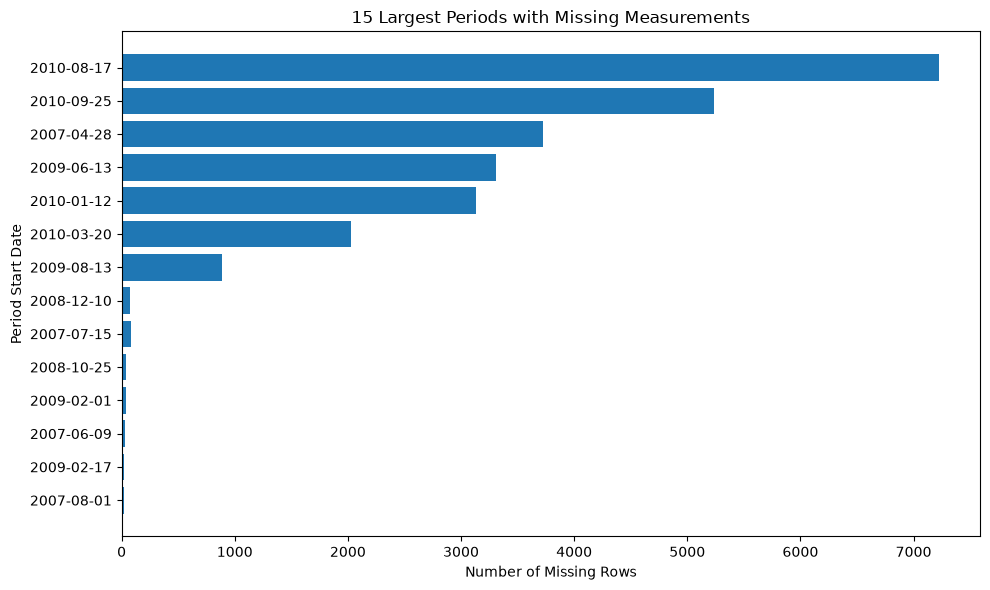

In [6]:
import matplotlib.pyplot as plt

top_periods = (
    missing_periods
    .sort_values("missing_rows", ascending=False)
    .head(15)
    .sort_values("missing_rows")
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_periods["start_datetime"].dt.strftime("%Y-%m-%d"),
    top_periods["missing_rows"]
)

plt.xlabel("Number of Missing Rows")
plt.ylabel("Period Start Date")
plt.title("15 Largest Periods with Missing Measurements")
plt.tight_layout()
plt.show()

This cell visualizes the 15 largest periods with missing measurements, making it easier to compare their sizes and identify the periods contributing most to missing data.

In [7]:
missing_periods["gap_category"] = pd.cut(
    missing_periods["missing_rows"],
    bins=[0, 5, 60, 1440, float("inf")],
    labels=[
        "Very short (1-5 rows)",
        "Short (6-60 rows)",
        "Medium (61-1440 rows)",
        "Long (over 1440 rows)"
    ]
)

gap_summary = (
    missing_periods
    .groupby("gap_category", observed=False)
    .agg(
        number_of_periods=("missing_rows", "size"),
        total_missing_rows=("missing_rows", "sum")
    )
)

display(gap_summary)

,number_of_periods,total_missing_rows
gap_category,,
Very short (1-5 rows),55,76
Short (6-60 rows),7,212
Medium (61-1440 rows),3,1044
Long (over 1440 rows),6,24647


This cell groups missing-data periods by their length and summarizes the number of periods and total missing rows in each category to support the selection of a suitable imputation strategy.

In [8]:
display(
    missing_periods[
        missing_periods["missing_rows"] <= 60
    ][
        [
            "start_datetime",
            "end_datetime",
            "missing_rows",
            "duration"
        ]
    ].sort_values("missing_rows")
)


,start_datetime,end_datetime,missing_rows,duration
61904,2007-01-28 17:13:00,2007-01-28 17:13:00,1,0 days 00:00:00
41828,2007-01-14 18:36:00,2007-01-14 18:36:00,1,0 days 00:00:00
236858,2007-06-01 19:14:00,2007-06-01 19:14:00,1,0 days 00:00:00
142580,2007-03-25 17:52:00,2007-03-25 17:52:00,1,0 days 00:00:00
244219,2007-06-06 21:56:00,2007-06-06 21:56:00,1,0 days 00:00:00
...,...,...,...,...
1138811,2009-02-17 10:06:00,2009-02-17 10:29:00,24,0 days 00:23:00
248296,2007-06-09 17:59:00,2007-06-09 18:31:00,33,0 days 00:32:00
1116194,2009-02-01 16:29:00,2009-02-01 17:06:00,38,0 days 00:37:00
973397,2008-10-25 10:28:00,2008-10-25 11:10:00,43,0 days 00:42:00


This cell lists missing-data periods containing up to 60 rows, allowing short gaps to be reviewed before selecting an appropriate imputation method.

In [9]:
short_gaps = missing_periods[
    missing_periods["missing_rows"] <= 5
].copy()

print("Number of very short gaps:", len(short_gaps))
print("Total missing rows in very short gaps:", short_gaps["missing_rows"].sum())

display(
    short_gaps[
        ["start_datetime", "end_datetime", "missing_rows", "duration"]
    ].sort_values("start_datetime")
)

Number of very short gaps: 55
Total missing rows in very short gaps: 76


,start_datetime,end_datetime,missing_rows,duration
6839,2006-12-21 11:23:00,2006-12-21 11:24:00,2,0 days 00:01:00
19722,2006-12-30 10:08:00,2006-12-30 10:09:00,2,0 days 00:01:00
41828,2007-01-14 18:36:00,2007-01-14 18:36:00,1,0 days 00:00:00
61904,2007-01-28 17:13:00,2007-01-28 17:13:00,1,0 days 00:00:00
98248,2007-02-22 22:58:00,2007-02-22 22:59:00,2,0 days 00:01:00
142580,2007-03-25 17:52:00,2007-03-25 17:52:00,1,0 days 00:00:00
236858,2007-06-01 19:14:00,2007-06-01 19:14:00,1,0 days 00:00:00
244219,2007-06-06 21:56:00,2007-06-06 21:56:00,1,0 days 00:00:00
247926,2007-06-09 11:44:00,2007-06-09 11:44:00,1,0 days 00:00:00
247946,2007-06-09 12:05:00,2007-06-09 12:05:00,1,0 days 00:00:00


In [13]:
# Identify all missing rows belonging to gaps of at most 5 rows
missing_mask = df.isna().any(axis=1)

group_id = (~missing_mask).cumsum()

gap_lengths = (
    missing_mask
    .groupby(group_id)
    .transform("sum")
)

short_gap_mask = missing_mask & (gap_lengths <= 5)

print("Rows in short gaps:", short_gap_mask.sum())

Rows in short gaps: 76


This cell calculates the total number of missing rows belonging to gaps containing five rows or fewer, helping quantify the amount of data potentially suitable for short-gap interpolation.

In [15]:
measurement_columns = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]

df_clean = df.set_index("Datetime").copy()

missing_mask = df_clean[measurement_columns].isna().any(axis=1)

group_id = (~missing_mask).cumsum()
gap_lengths = missing_mask.groupby(group_id).transform("sum")
short_gap_mask = missing_mask & (gap_lengths <= 5)

interpolated_values = df_clean[measurement_columns].interpolate(
    method="time",
    limit=5,
    limit_area="inside"
)

df_clean.loc[short_gap_mask, measurement_columns] = (
    interpolated_values.loc[short_gap_mask, measurement_columns]
)

print("Rows interpolated:", short_gap_mask.sum())
print(
    "Remaining missing rows:",
    df_clean[measurement_columns].isna().any(axis=1).sum()
)
print(
    "Remaining missing values:",
    df_clean[measurement_columns].isna().sum().sum()
)

Rows interpolated: 76
Remaining missing rows: 25903
Remaining missing values: 181321


This cell applies time-based interpolation to missing measurements in gaps containing at most five consecutive rows. Only these short gaps are filled, while longer gaps remain unchanged. The final checks report the number of interpolated rows and the remaining missing data.

In [16]:
print("Dataset shape:", df_clean.shape)

print("\nMissing values per measurement column:")
display(df_clean[measurement_columns].isna().sum())

print("\nNegative values after interpolation:")
display((df_clean[measurement_columns] < 0).sum())

print("\nDuplicate timestamps:", df_clean.index.duplicated().sum())

print("\nDataset index sorted:", df_clean.index.is_monotonic_increasing)

Dataset shape: (2075259, 9)

Missing values per measurement column:


Global_active_power      25903
Global_reactive_power    25903
Voltage                  25903
Global_intensity         25903
Sub_metering_1           25903
Sub_metering_2           25903
Sub_metering_3           25903
dtype: int64


Negative values after interpolation:


Global_active_power      0
Global_reactive_power    0
Voltage                  0
Global_intensity         0
Sub_metering_1           0
Sub_metering_2           0
Sub_metering_3           0
dtype: int64


Duplicate timestamps: 0

Dataset index sorted: True


This cell validates the dataset after short-gap interpolation by checking its shape, remaining missing values, negative measurements, duplicate timestamps, and chronological ordering.

In [17]:
remaining_missing_mask = (
    df_clean[measurement_columns]
    .isna()
    .any(axis=1)
)

remaining_group_id = (~remaining_missing_mask).cumsum()

remaining_gap_lengths = (
    remaining_missing_mask
    .groupby(remaining_group_id)
    .transform("sum")
)

remaining_gap_summary = (
    remaining_gap_lengths[remaining_missing_mask]
    .value_counts()
    .sort_index()
)

print("Remaining missing rows:", remaining_missing_mask.sum())
print("\nNumber of missing rows by gap length:")
display(remaining_gap_summary)

Remaining missing rows: 25903

Number of missing rows by gap length:


6          6
21        21
24        24
33        33
38        38
43        43
47        47
70        70
83        83
891      891
2027    2027
3129    3129
3305    3305
3723    3723
5237    5237
7226    7226
Name: count, dtype: int64

This cell analyzes the remaining missing data after short-gap interpolation. It groups consecutive missing rows by gap length and summarizes how many missing rows remain for each gap size.

In [18]:
gap_categories = pd.cut(
    remaining_gap_lengths[remaining_missing_mask],
    bins=[0, 60, 1440, float("inf")],
    labels=[
        "Short (6-60 rows)",
        "Medium (61-1440 rows)",
        "Long (over 1440 rows)"
    ]
)

gap_category_summary = gap_categories.value_counts().sort_index()

display(gap_category_summary)

Short (6-60 rows)          212
Medium (61-1440 rows)     1044
Long (over 1440 rows)    24647
Name: count, dtype: int64

This cell categorizes the remaining missing rows by gap length: short gaps contain 6–60 rows, medium gaps contain 61–1,440 rows, and long gaps contain more than 1,440 rows. This summary supports the choice of an appropriate missing-data strategy.

In [19]:
from pathlib import Path

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

OUTPUT_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "household_power_consumption_cleaned.csv"
)

OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)

df_clean.to_csv(OUTPUT_PATH, index=True, index_label="Datetime")

print("Cleaned dataset saved to:", OUTPUT_PATH)
print("Dataset shape:", df_clean.shape)
print(
    "Remaining missing values:",
    df_clean[measurement_columns].isna().sum().sum()
)

Cleaned dataset saved to: c:\Users\hp\smart-energy-consumption-prediction\data\processed\household_power_consumption_cleaned.csv
Dataset shape: (2075259, 9)
Remaining missing values: 181321


This cell saves the cleaned dataset to the processed data directory. Short missing gaps have been interpolated, while longer gaps remain missing to avoid introducing potentially misleading values. The final checks confirm the saved dataset's dimensions and remaining missing values.


In [20]:
processed_df = pd.read_csv(OUTPUT_PATH)

print("Dataset shape:", processed_df.shape)
print("\nColumns:")
display(processed_df.columns.tolist())

print("\nFirst 5 rows:")
display(processed_df.head())

print("\nDatetime column type:", processed_df["Datetime"].dtype)

Dataset shape: (2075259, 10)

Columns:


['Datetime',
 'Date',
 'Time',
 'Global_active_power',
 'Global_reactive_power',
 'Voltage',
 'Global_intensity',
 'Sub_metering_1',
 'Sub_metering_2',
 'Sub_metering_3']


First 5 rows:


,Datetime,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,2006-12-16 17:24:00,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,2006-12-16 17:25:00,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,2006-12-16 17:26:00,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,2006-12-16 17:27:00,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,2006-12-16 17:28:00,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0



Datetime column type: str


This cell reloads the saved CSV file and checks its dimensions, column names, first five rows, and the data type of the Datetime column.

In [21]:
processed_df["Datetime"] = pd.to_datetime(
    processed_df["Datetime"],
    errors="raise"
)

processed_df = processed_df.set_index("Datetime")

print("Datetime index type:", type(processed_df.index))
print("Index sorted:", processed_df.index.is_monotonic_increasing)
print("Duplicate timestamps:", processed_df.index.duplicated().sum())

Datetime index type: <class 'pandas.DatetimeIndex'>
Index sorted: True
Duplicate timestamps: 0


This cell converts the Datetime column into a proper datetime format and sets it as the DataFrame index. It then checks the index type, chronological ordering, and duplicate timestamps.

In [23]:
print("Current columns:")
display(processed_df.columns.tolist())

print("\nCurrent index name:", processed_df.index.name)


Current columns:


['Date',
 'Time',
 'Global_active_power',
 'Global_reactive_power',
 'Voltage',
 'Global_intensity',
 'Sub_metering_1',
 'Sub_metering_2',
 'Sub_metering_3']


Current index name: Datetime


In [24]:
print("Index type:", type(processed_df.index))
print("Chronological order:", processed_df.index.is_monotonic_increasing)
print("Duplicate timestamps:", processed_df.index.duplicated().sum())

Index type: <class 'pandas.DatetimeIndex'>
Chronological order: True
Duplicate timestamps: 0


In [25]:
processed_df = processed_df.drop(columns=["Date", "Time"])

processed_df.to_csv(
    OUTPUT_PATH,
    index=True,
    index_label="Datetime"
)

print("Final dataset shape:", processed_df.shape)
print(
    "Remaining missing values:",
    processed_df[measurement_columns].isna().sum().sum()
)
print("Saved to:", OUTPUT_PATH)

Final dataset shape: (2075259, 7)
Remaining missing values: 181321
Saved to: c:\Users\hp\smart-energy-consumption-prediction\data\processed\household_power_consumption_cleaned.csv


This cell removes the redundant Date and Time columns, saves the cleaned dataset with Datetime as the index, and reports the final dataset dimensions and remaining missing values.

## Conclusion

The dataset was cleaned using a time-based interpolation strategy for short missing gaps containing up to five consecutive rows. A total of 76 rows were interpolated, while longer missing periods were preserved to avoid introducing potentially misleading values.

The cleaned dataset contains 2,075,259 rows and 7 numerical measurement columns, with 181,321 missing values remaining. The datetime index was validated, the chronological order was preserved, and no duplicate timestamps were found.

The processed dataset was saved to `data/processed/household_power_consumption_cleaned.csv` for use in subsequent analysis.